## Load Dataset

In [1]:
import pandas as pd
df=pd.read_csv("../data/solar data.csv")

## Data Inspection

In [2]:
df.head(2)

,Date,Time,DateTime,Country,DC_Power,AC_Power,Ambient_Temperature,Module_Temperature,Irradiation,Day,Month,Hour,Daily_Yield,Total_Yield
0,2024-01-01,0,2024-01-01 00:00:00,Norway,0.0,0.0,-10.15,-3.33,0.039,1,1,0,145.722,145.722
1,2024-01-01,1,2024-01-01 01:00:00,Norway,0.0,0.0,-10.06,-3.50,0.014,1,1,1,145.722,291.444


In [3]:
df.tail(2)

,Date,Time,DateTime,Country,DC_Power,AC_Power,Ambient_Temperature,Module_Temperature,Irradiation,Day,Month,Hour,Daily_Yield,Total_Yield
35134,2024-12-31,22,2024-12-31 22:00:00,Australia,0.0,0.0,8.36,13.61,0.017,31,12,22,490.155,3644722.485
35135,2024-12-31,23,2024-12-31 23:00:00,Australia,0.0,0.0,8.16,12.95,0.000,31,12,23,490.155,3645212.640


In [4]:
df.shape

(35136, 14)

In [5]:
df.columns

Index(['Date', 'Time', 'DateTime', 'Country', 'DC_Power', 'AC_Power',
       'Ambient_Temperature', 'Module_Temperature', 'Irradiation', 'Day',
       'Month', 'Hour', 'Daily_Yield', 'Total_Yield'],
      dtype='object')

In [6]:
df.dtypes

Date                    object
Time                     int64
DateTime                object
Country                 object
DC_Power               float64
AC_Power               float64
Ambient_Temperature    float64
Module_Temperature     float64
Irradiation            float64
Day                      int64
Month                    int64
Hour                     int64
Daily_Yield            float64
Total_Yield            float64
dtype: object

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35136 entries, 0 to 35135
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Date                 35136 non-null  object 
 1   Time                 35136 non-null  int64  
 2   DateTime             35136 non-null  object 
 3   Country              35136 non-null  object 
 4   DC_Power             35136 non-null  float64
 5   AC_Power             35136 non-null  float64
 6   Ambient_Temperature  35136 non-null  float64
 7   Module_Temperature   35136 non-null  float64
 8   Irradiation          35136 non-null  float64
 9   Day                  35136 non-null  int64  
 10  Month                35136 non-null  int64  
 11  Hour                 35136 non-null  int64  
 12  Daily_Yield          35136 non-null  float64
 13  Total_Yield          35136 non-null  float64
dtypes: float64(7), int64(4), object(3)
memory usage: 3.8+ MB


In [8]:
df.describe()

,Time,DC_Power,AC_Power,Ambient_Temperature,Module_Temperature,Irradiation,Day,Month,Hour,Daily_Yield,Total_Yield
count,35136.000000,35136.000000,35136.000000,35136.000000,35136.000000,35136.000000,35136.000000,35136.000000,35136.000000,35136.000000,3.513600e+04
mean,11.500000,18.328791,16.597491,19.471019,24.475755,0.303354,15.756831,6.513661,11.500000,398.339796,1.756229e+06
std,6.922285,22.507191,20.414370,11.857084,11.886490,0.360226,8.811655,3.451283,6.922285,85.781465,1.050192e+06
min,0.000000,0.000000,0.000000,-11.480000,-7.910000,0.000000,1.000000,1.000000,0.000000,140.666000,1.457220e+02
25%,5.750000,0.000000,0.000000,13.297500,18.350000,0.000000,8.000000,4.000000,5.750000,359.825750,8.425283e+05
50%,11.500000,0.000000,0.000000,21.130000,26.225000,0.075500,16.000000,7.000000,11.500000,420.060000,1.770125e+06
75%,17.250000,36.568500,32.928250,28.360000,33.320000,0.603000,23.000000,10.000000,17.250000,458.513750,2.616968e+06
max,23.000000,83.478000,81.336000,39.360000,46.940000,1.214000,31.000000,12.000000,23.000000,520.186000,4.064366e+06


In [9]:
df.nunique()

Date                     366
Time                      24
DateTime                8784
Country                    4
DC_Power               15310
AC_Power               15069
Ambient_Temperature     4789
Module_Temperature      4940
Irradiation             1109
Day                       31
Month                     12
Hour                      24
Daily_Yield             1462
Total_Yield            35136
dtype: int64

## Data Quality Check

In [10]:
df.isnull().sum()

Date                   0
Time                   0
DateTime               0
Country                0
DC_Power               0
AC_Power               0
Ambient_Temperature    0
Module_Temperature     0
Irradiation            0
Day                    0
Month                  0
Hour                   0
Daily_Yield            0
Total_Yield            0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
numerical_col=df.select_dtypes(include=["int64","float64"]).columns
numerical_col

Index(['Time', 'DC_Power', 'AC_Power', 'Ambient_Temperature',
       'Module_Temperature', 'Irradiation', 'Day', 'Month', 'Hour',
       'Daily_Yield', 'Total_Yield'],
      dtype='object')

In [13]:
categorical_col=df.select_dtypes(include=["object","category"]).columns
categorical_col

Index(['Date', 'DateTime', 'Country'], dtype='object')

###### Now "Date" and "DateTime" columns are in objects instead of date time format.So we needed to convert object into date time so we can analyse time-based patterns

In [14]:
df["Date"]=pd.to_datetime(df["Date"])
df["DateTime"]=pd.to_datetime(df["DateTime"])

In [15]:
df.dtypes

Date                   datetime64[ns]
Time                            int64
DateTime               datetime64[ns]
Country                        object
DC_Power                      float64
AC_Power                      float64
Ambient_Temperature           float64
Module_Temperature            float64
Irradiation                   float64
Day                             int64
Month                           int64
Hour                            int64
Daily_Yield                   float64
Total_Yield                   float64
dtype: object

#### Negative values in each column

In [16]:
(df.select_dtypes(include="number")<0).sum()

Time                      0
DC_Power                  0
AC_Power                  0
Ambient_Temperature    3470
Module_Temperature     2342
Irradiation               0
Day                       0
Month                     0
Hour                      0
Daily_Yield               0
Total_Yield               0
dtype: int64

###### Negative values were found in Ambient_Temperature and Module_Temperature.
###### These values are valid because temperatures can fall below zero, particularly in colder region such as Norway.
###### Therefore, these values are retained and are not considered data errors.

## OUTLIER DETECTION USING IQR

In [17]:
Q1=df.select_dtypes(include="number").quantile(0.25)
Q3=df.select_dtypes(include="number").quantile(0.75)
IQR=Q3-Q1
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
outliers=((df.select_dtypes(include="number")<lower_bound) | (df.select_dtypes(include="number")>upper_bound)).sum()
outliers

Time                      0
DC_Power                  0
AC_Power                  0
Ambient_Temperature     838
Module_Temperature      863
Irradiation               0
Day                       0
Month                     0
Hour                      0
Daily_Yield            2304
Total_Yield               0
dtype: int64

###### IQR analysis identified potential outliers in Ambient_Temperature, Module_Temperature and Daily_Yield.
###### These observations require investigation before removal.
###### They may represent genuine environmental conditions or variations in solar power generation.Therefore, the observations are retained.

## EDA

### Univariate Analysis

#### Target variable distribution

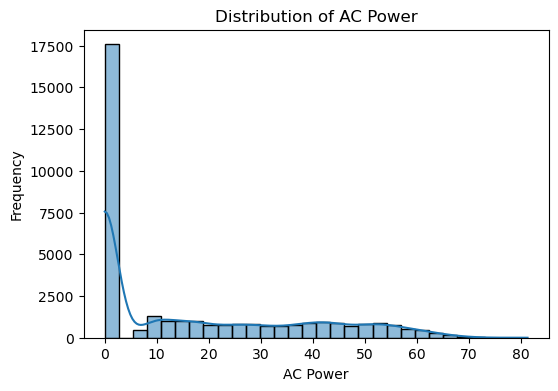

In [18]:
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
plt.figure(figsize=(6,4))
sns.histplot(df["AC_Power"],bins=30,kde=True)
plt.title("Distribution of AC Power")
plt.xlabel("AC Power")
plt.ylabel("Frequency")
plt.show()

###### AC_Power has a large concentration of observations at zero because solar power generation is absent or very low during nighttime hours.
###### Power generation increases during daylight hours,with higher values around midday.

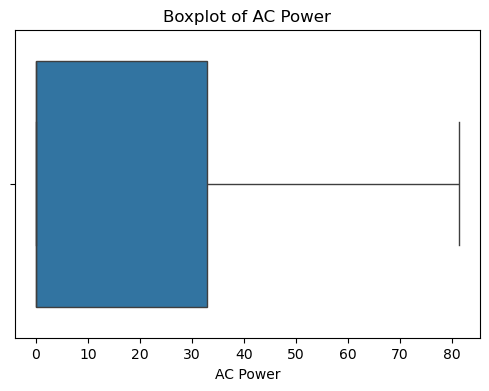

In [19]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df["AC_Power"])
plt.title("Boxplot of AC Power")
plt.xlabel("AC Power")
plt.show()

#### Other features distribution

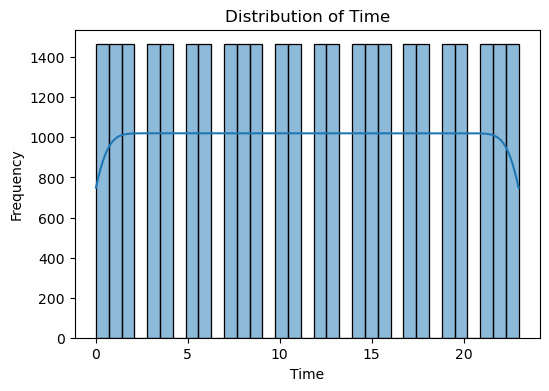

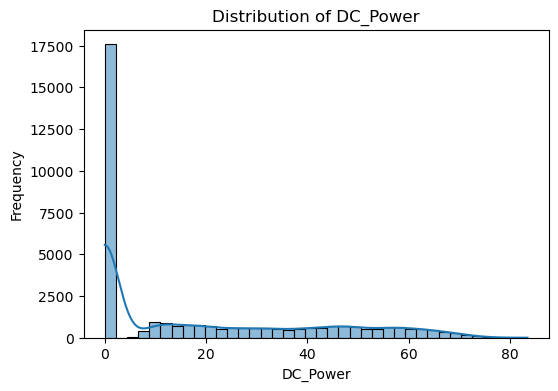

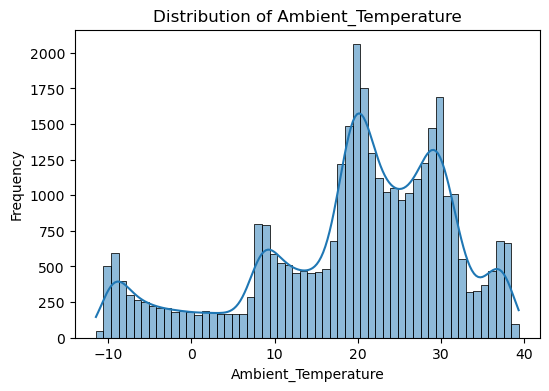

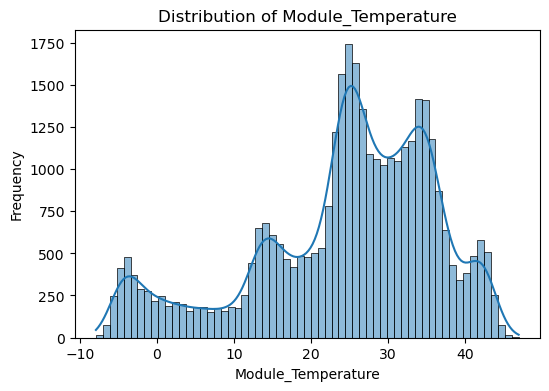

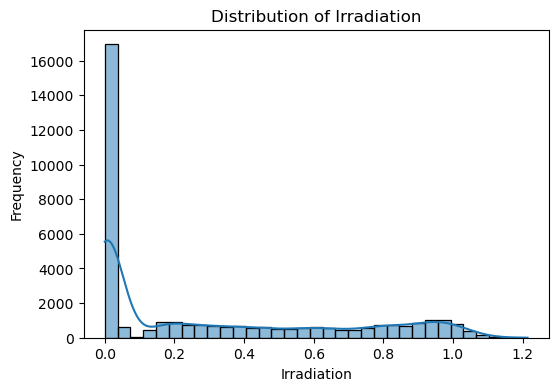

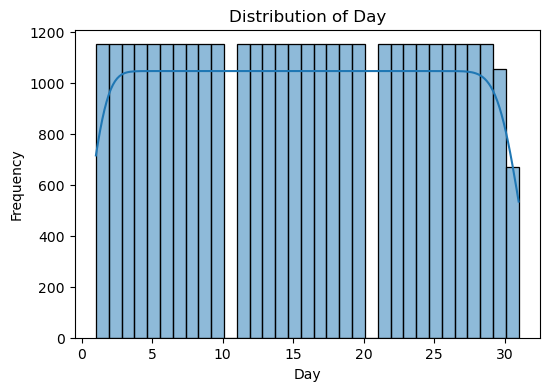

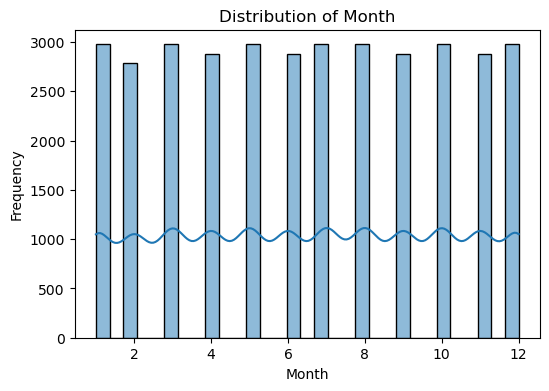

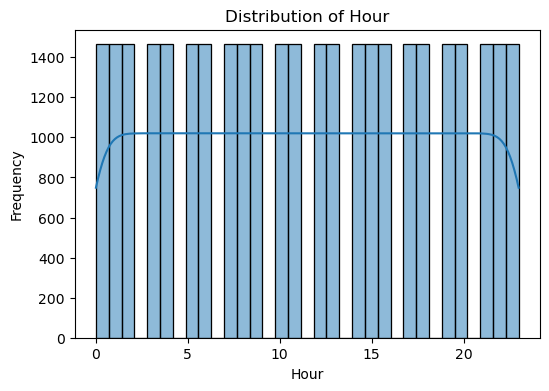

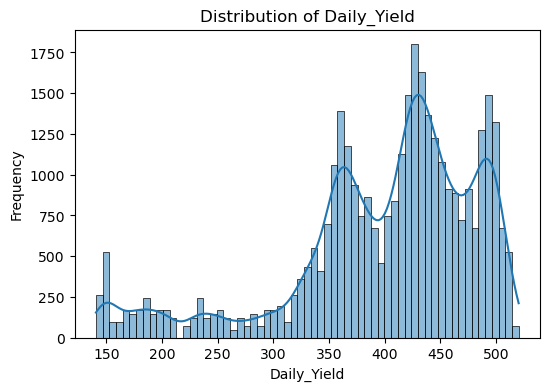

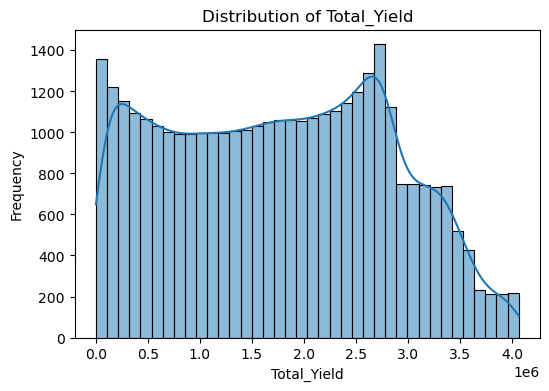

In [20]:
features=df.drop(columns=["AC_Power"])
numerical_features=features.select_dtypes(include="number")
for i in numerical_features.columns:
    plt.figure(figsize=(6,4))
    sns.histplot(features[i],kde=True)
    plt.title(f"Distribution of {i}")
    plt.xlabel(i)
    plt.ylabel("Frequency")
    plt.show()

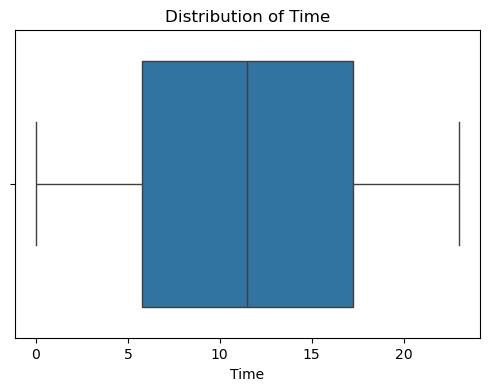

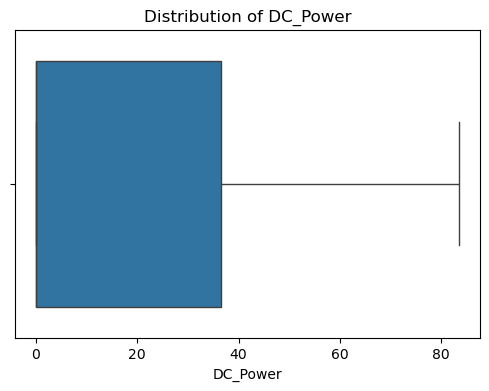

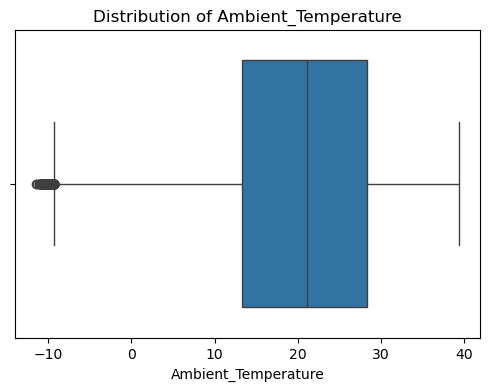

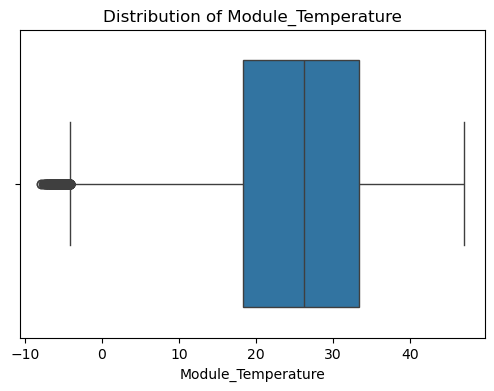

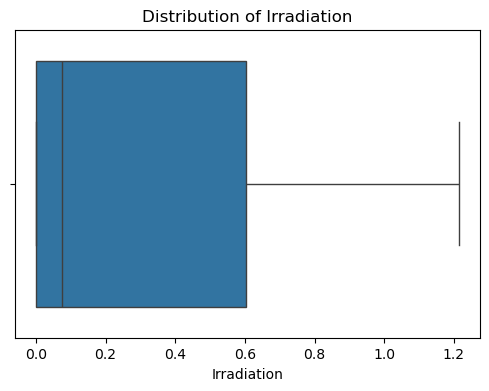

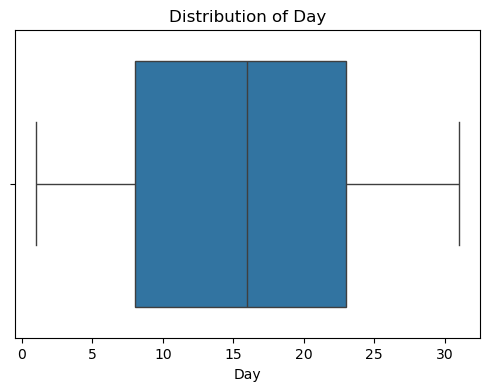

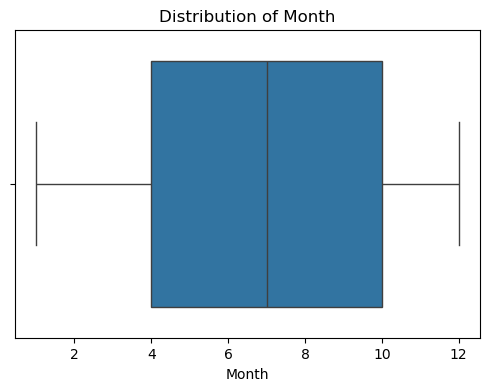

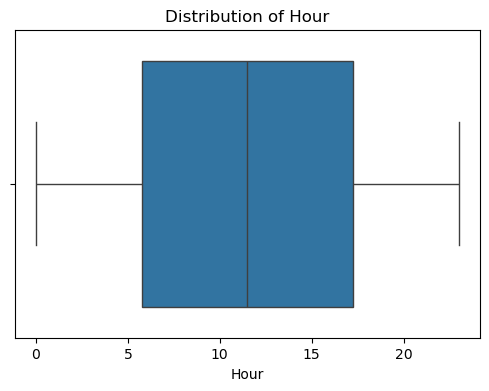

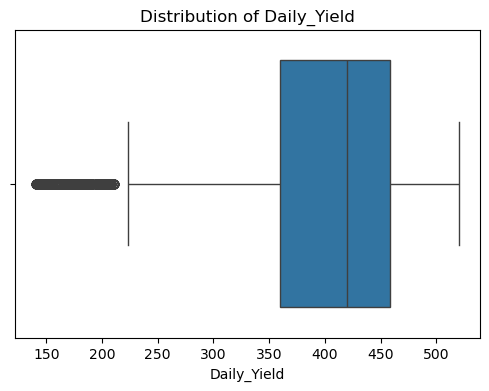

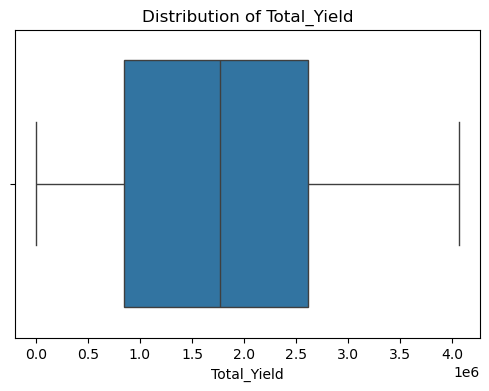

In [21]:
features=df.drop(columns=["AC_Power"])
numerical_features=features.select_dtypes(include="number")
for i in numerical_features.columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=features[i])
    plt.title(f"Distribution of {i}")
    plt.xlabel(i)
    plt.show()

#### Countplot for categorical features

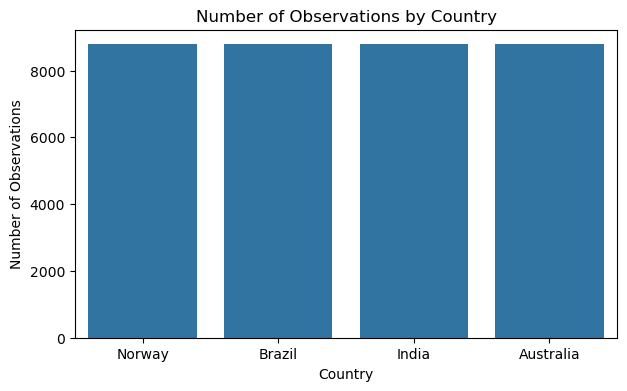

In [36]:
plt.figure(figsize=(7,4))
sns.countplot(x=df["Country"])
plt.ylabel("Number of Observations")
plt.title("Number of Observations by Country")
plt.show()

### Bivariate Analysis

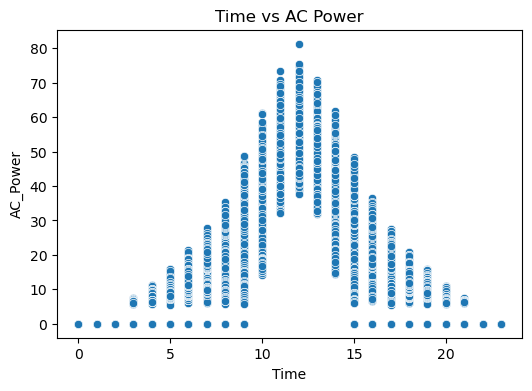

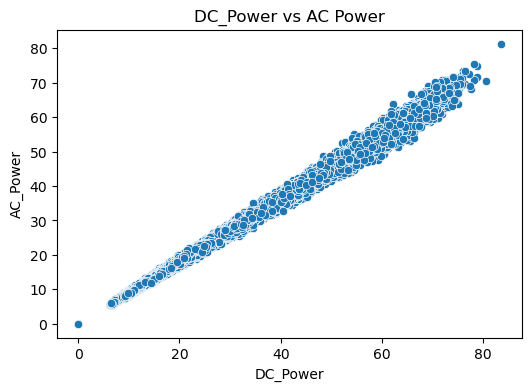

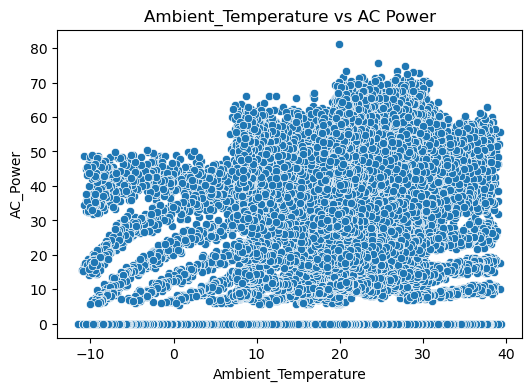

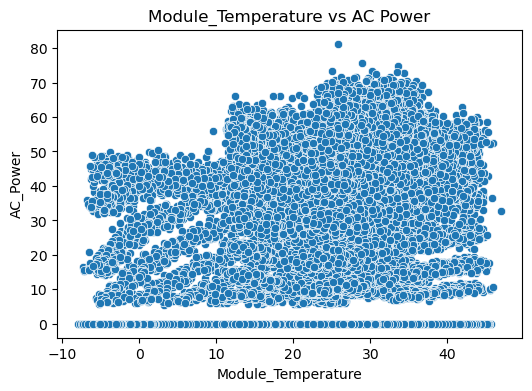

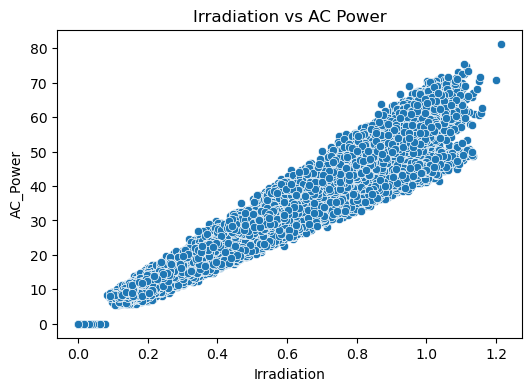

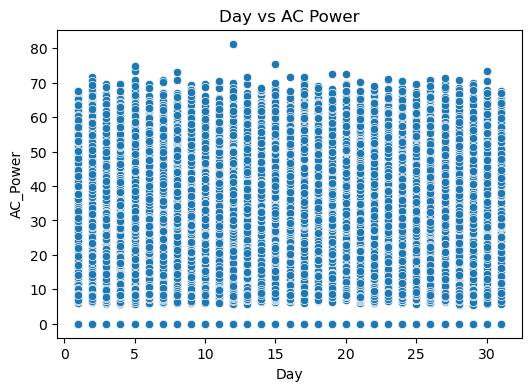

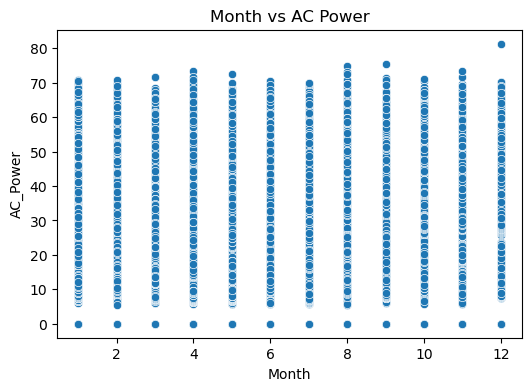

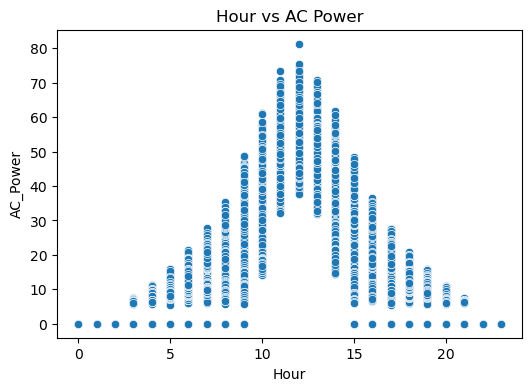

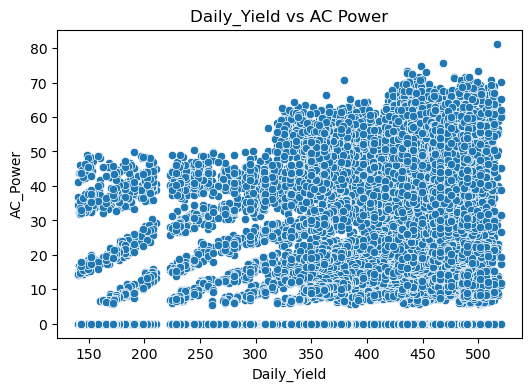

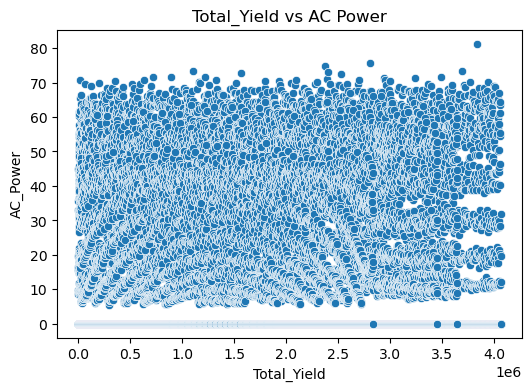

In [23]:
features=df.drop(columns=["AC_Power"])
numerical_features=features.select_dtypes(include="number")
for i in numerical_features.columns:
    plt.figure(figsize=(6,4))
    sns.scatterplot(x=features[i],y=df["AC_Power"])
    plt.title(f"{i} vs AC Power")
    plt.xlabel(i)
    plt.show()

#### Observations

1. Time vs AC_Power: AC_Power is higher around midday and lower during morning and evening.

2. DC_Power vs AC_Power: AC_Power increases when DC_Power increases.

3. Ambient_Temperature vs AC_Power: No clear relationship is observed.

4. Module_Temperature vs AC_Power: No clear relationship is observed.

5. Irradiation vs AC_Power: AC_Power generally increases when Irradiation increases.

6. Day vs AC_Power: No clear relationship is observed.

7. Month vs AC_Power: AC_Power varies across different months.

8. Hour vs AC_Power: AC_Power is higher around midday and lower during night hours.

9. Daily_Yield vs AC_Power: Higher Daily_Yield values generally occur with higher AC_Power values but no clear relationship occurs.

10. Total_Yield vs AC_Power: No clear relationship is observed.

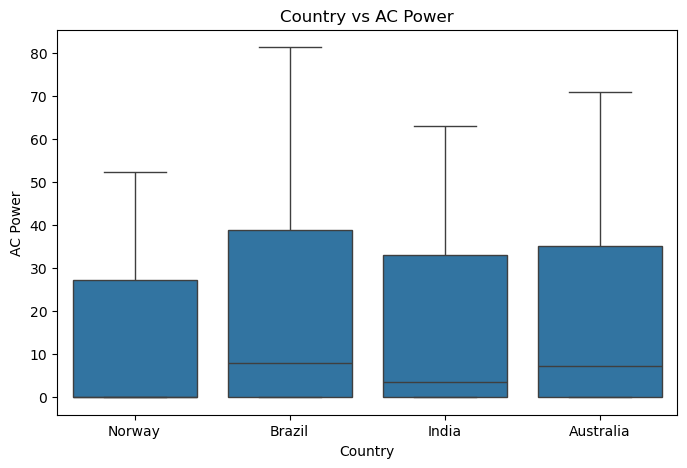

In [24]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df["Country"],y=df["AC_Power"])
plt.title("Country vs AC Power")
plt.xlabel("Country")
plt.ylabel("AC Power")
plt.show()

### Time Based Analysis

##### For this analysis we are using 4 columns :"Date","Month","Hour","DateTime"

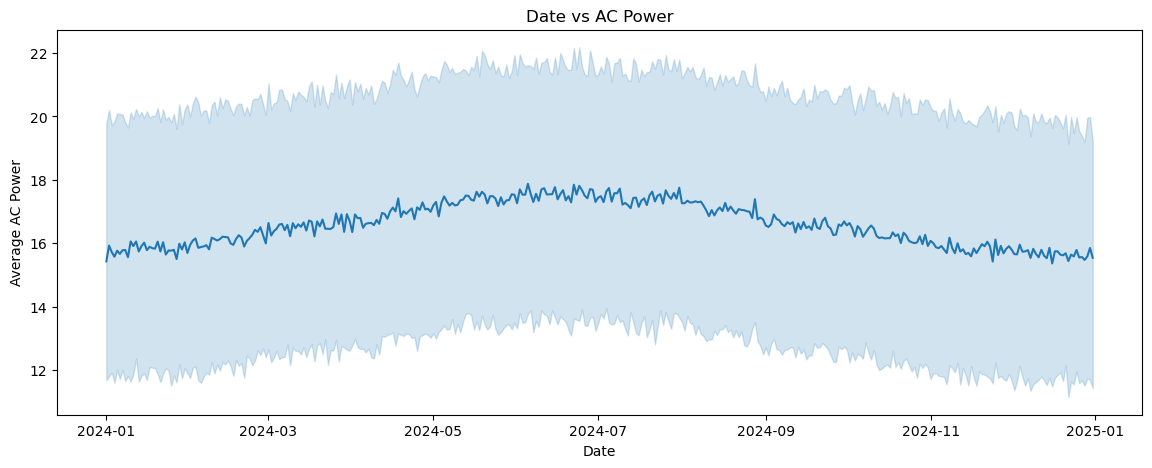

In [25]:
plt.figure(figsize=(14,5))
sns.lineplot(x=df["Date"],y=df["AC_Power"],estimator="mean")
plt.title("Date vs AC Power")
plt.xlabel("Date")
plt.ylabel("Average AC Power")
plt.show()

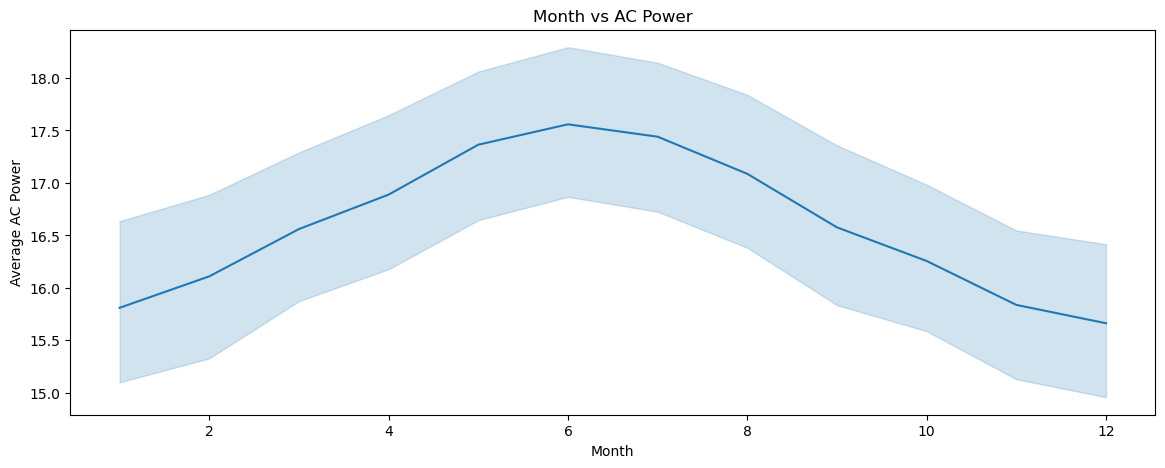

In [26]:
plt.figure(figsize=(14,5))
sns.lineplot(x=df["Month"],y=df["AC_Power"],estimator="mean")
plt.title("Month vs AC Power")
plt.xlabel("Month")
plt.ylabel("Average AC Power")
plt.show()

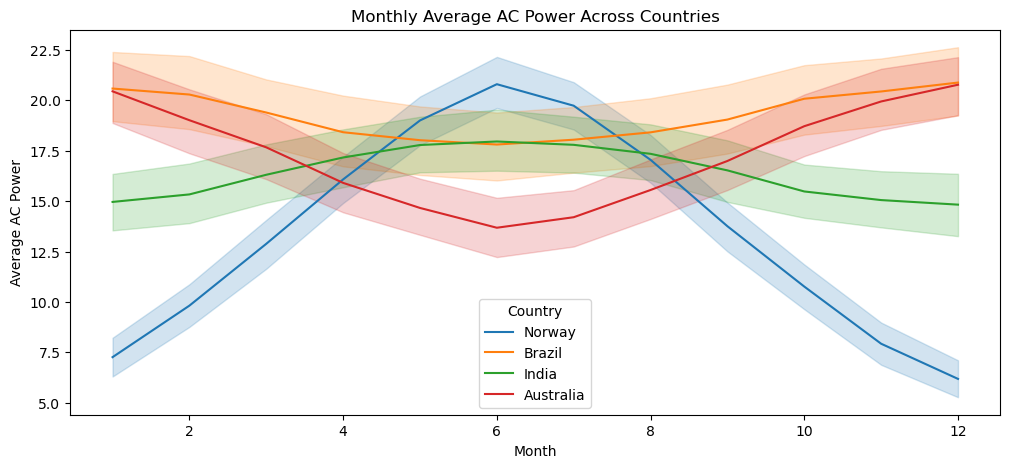

In [35]:
plt.figure(figsize=(12,5))
sns.lineplot(data=df,x="Month",y="AC_Power",hue="Country",estimator="mean")
plt.title("Monthly Average AC Power Across Countries")
plt.xlabel("Month")
plt.ylabel("Average AC Power")
plt.show()

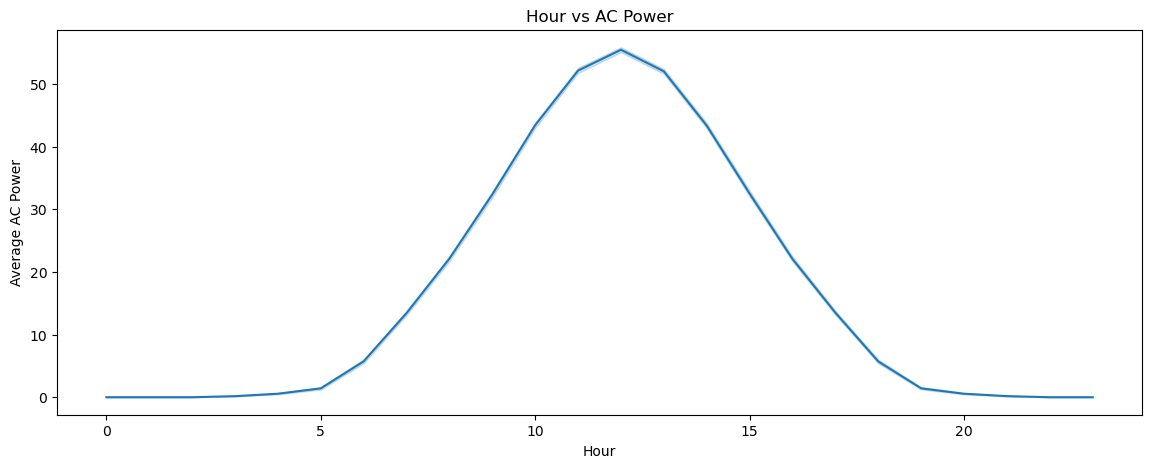

In [27]:
plt.figure(figsize=(14,5))
sns.lineplot(x=df["Hour"],y=df["AC_Power"],estimator="mean")
plt.title("Hour vs AC Power")
plt.xlabel("Hour")
plt.ylabel("Average AC Power")
plt.show()

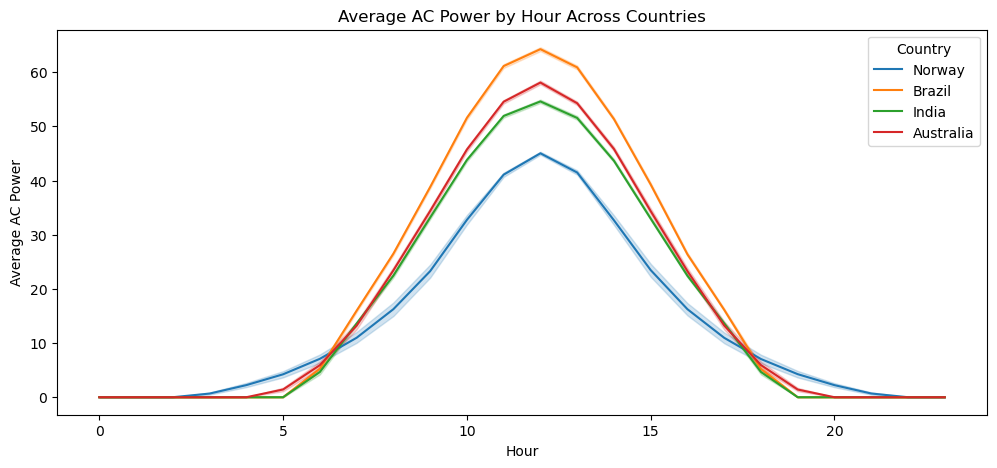

In [33]:
plt.figure(figsize=(12,5))
sns.lineplot(data=df,x="Hour",y="AC_Power",hue="Country",estimator="mean")
plt.title("Average AC Power by Hour Across Countries")
plt.xlabel("Hour")
plt.ylabel("Average AC Power")
plt.show()

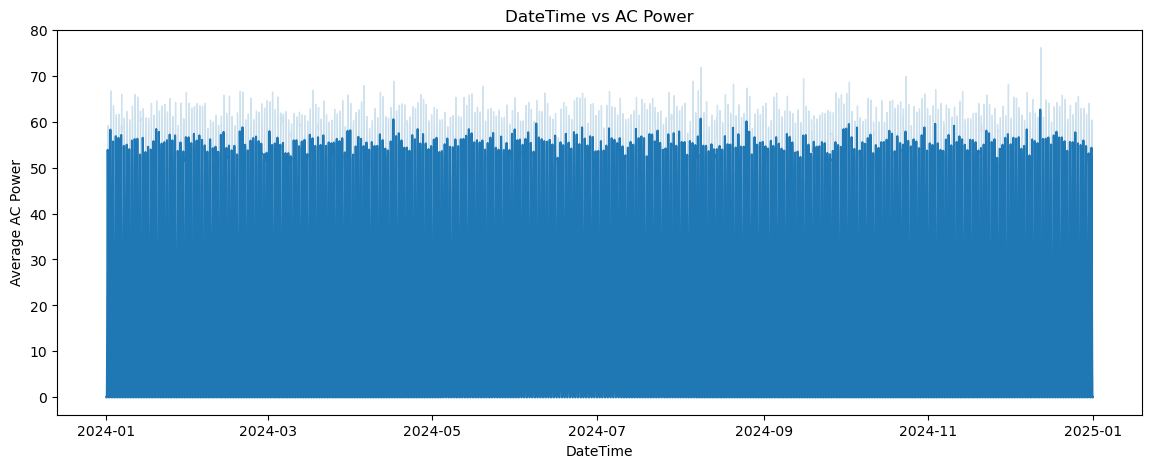

In [28]:
plt.figure(figsize=(14,5))
sns.lineplot(x=df["DateTime"],y=df["AC_Power"],estimator="mean")
plt.title("DateTime vs AC Power")
plt.xlabel("DateTime")
plt.ylabel("Average AC Power")
plt.show()

### Multivariate Analysis

#### Correlation Analysis

In [29]:
corr=df.corr(numeric_only=True)
corr

,Time,DC_Power,AC_Power,Ambient_Temperature,Module_Temperature,Irradiation,Day,Month,Hour,Daily_Yield,Total_Yield
Time,1.000000e+00,0.058750,0.058726,0.000329,0.000463,0.058941,-8.465022e-17,-2.994430e-15,1.000000e+00,5.292523e-16,0.002626
DC_Power,5.874971e-02,1.000000,0.999119,0.095170,0.094925,0.987042,-5.407597e-05,-5.221162e-03,5.874971e-02,1.729377e-01,0.015847
AC_Power,5.872619e-02,0.999119,1.000000,0.098487,0.098222,0.985320,3.604097e-04,-5.219466e-03,5.872619e-02,1.750839e-01,0.016846
Ambient_Temperature,3.285319e-04,0.095170,0.098487,1.000000,0.995566,0.053477,1.001890e-03,-1.005696e-01,3.285319e-04,5.623981e-01,0.017730
Module_Temperature,4.632499e-04,0.094925,0.098222,0.995566,1.000000,0.053403,1.240181e-03,-1.001532e-01,4.632499e-04,5.605665e-01,0.017708
Irradiation,5.894110e-02,0.987042,0.985320,0.053477,0.053403,1.000000,-1.925679e-04,-8.190633e-03,5.894110e-02,1.338439e-01,-0.004940
Day,-8.465022e-17,-0.000054,0.000360,0.001002,0.001240,-0.000193,1.000000e+00,6.443300e-03,-8.385452e-17,2.058497e-03,0.086430
Month,-2.994430e-15,-0.005221,-0.005219,-0.100570,-0.100153,-0.008191,6.443300e-03,1.000000e+00,-2.992805e-15,-2.981123e-02,0.974270
Hour,1.000000e+00,0.058750,0.058726,0.000329,0.000463,0.058941,-8.385452e-17,-2.992805e-15,1.000000e+00,5.292523e-16,0.002626
Daily_Yield,5.292523e-16,0.172938,0.175084,0.562398,0.560566,0.133844,2.058497e-03,-2.981123e-02,5.292523e-16,1.000000e+00,0.095298


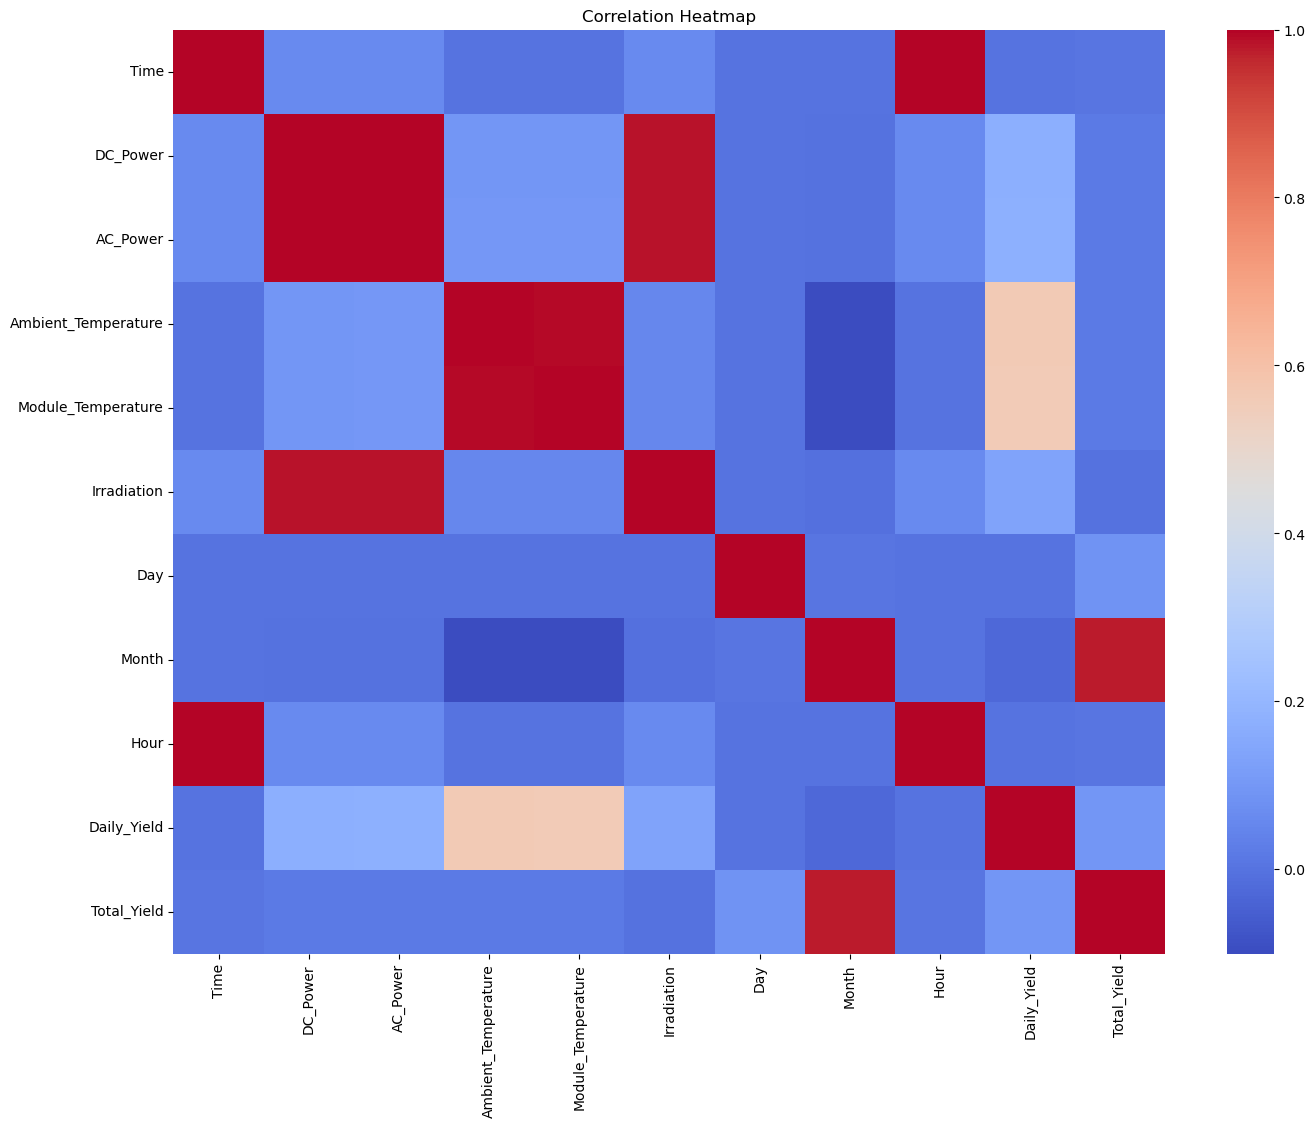

In [30]:
plt.figure(figsize=(16,12))
sns.heatmap(corr,cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [31]:
corr_features=corr["AC_Power"].drop("AC_Power")
select_value=corr_features.sort_values()
select_value

Month                 -0.005219
Day                    0.000360
Total_Yield            0.016846
Time                   0.058726
Hour                   0.058726
Module_Temperature     0.098222
Ambient_Temperature    0.098487
Daily_Yield            0.175084
Irradiation            0.985320
DC_Power               0.999119
Name: AC_Power, dtype: float64

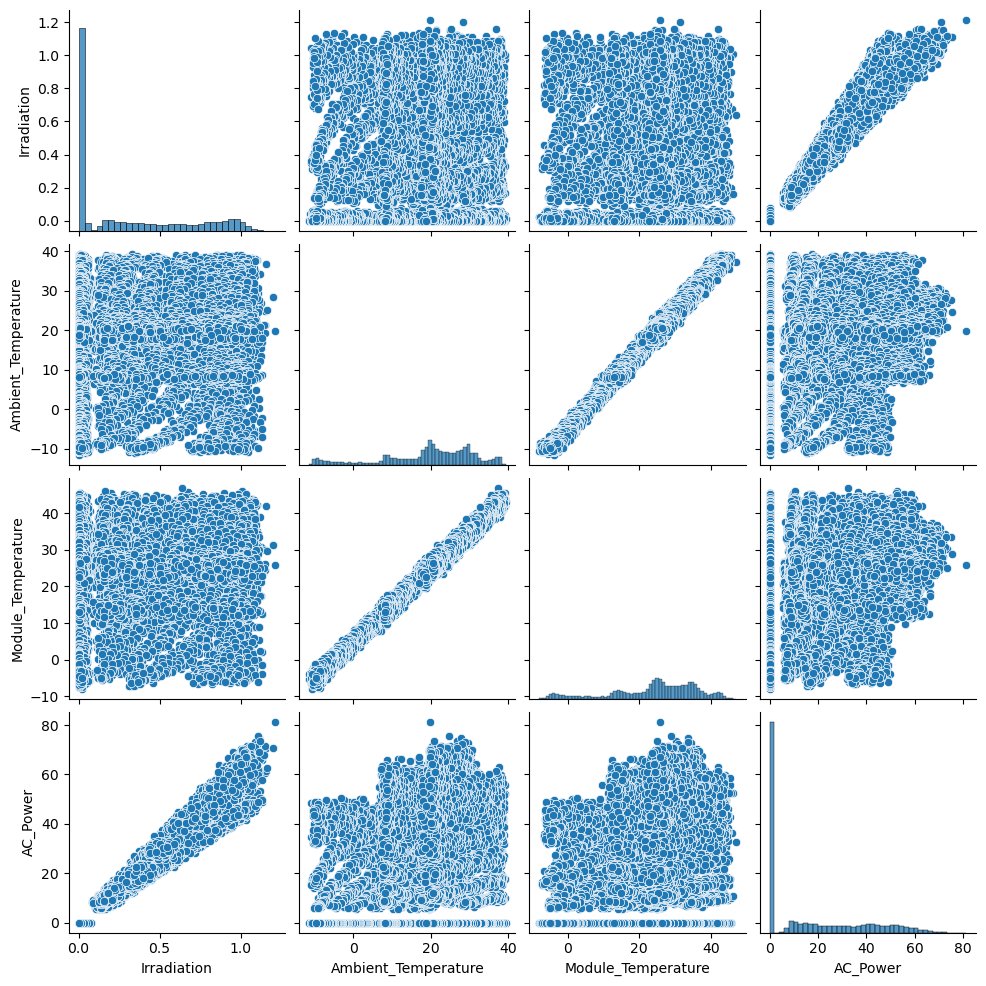

In [32]:
select_features=["Irradiation","Ambient_Temperature","Module_Temperature","AC_Power"]
sns.pairplot(df[select_features])
plt.show()